# ClearPath Exam Check: Decision Tree Training Notebook
**CST 9/L Final Project · Web-based application using supervised machine learning**

**Algorithm (supervised):** Decision Tree Classifier inside a scikit-learn `Pipeline` (StandardScaler, then DecisionTreeClassifier).

**Goal:** from six weekly study habits, predict whether a student is **On Track** (likely to score 70 or higher) or **Needs Support**. The website runs the exported model in the browser.

**How to run in Google Colab:** upload this notebook, choose *Runtime > Run all*, and upload `notebook.csv` when asked. At the end, download `model.js` and place it beside `index.html` in the website folder.

**Important:** the exam score is deliberately NOT a model input. In this dataset the label is exactly `exam_score >= 70`, so using it would hand the model the answer (target leakage) and give a fake 100%.

## 1. Load the dataset

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd

# Look for notebook.csv next to this notebook; in Google Colab, ask for an upload.
csv_path = next((p for p in [Path.cwd() / "notebook.csv", Path.cwd() / "data/notebook.csv"] if p.is_file()), None)
if csv_path is None:
    from google.colab import files
    uploaded = files.upload()
    csv_path = Path(next(iter(uploaded)))

students = pd.read_csv(csv_path)
print("Records:", students.shape[0], "| Columns:", students.shape[1])
students.head()

Records: 10000 | Columns: 8


,study_hours,attendance,sleep_hours,internet_usage,assignments_completed,previous_score,exam_score,placement_status
0,7,56,8,7,10,62,100.00,Placed
1,4,69,5,3,8,56,100.00,Placed
2,11,60,7,6,10,45,100.00,Placed
3,8,99,9,8,4,55,90.17,Placed
4,5,52,8,6,8,40,78.82,Placed


## 2. Dataset description and cleaning checks
Each row is one student. Columns: `study_hours`, `attendance` (%), `sleep_hours`, `internet_usage`, `assignments_completed`, `previous_score`, `exam_score`, `placement_status`.
The units of `study_hours` and `internet_usage` were not documented with the file and still need to be confirmed.

In [2]:
print("Missing values per column:")
print(students.isna().sum().to_string())
print("\nDuplicate rows:", students.duplicated().sum())
print("\nColumn ranges:")
display(students.describe().T[["min", "mean", "max"]].round(2))

# The label in this file is exactly the rule exam_score >= 70. Check it, because it decides which columns are allowed as inputs.
rule = np.where(students["exam_score"] >= 70, "Placed", "Not Placed")
matches = int((rule == students["placement_status"]).sum())
print(f"\nplacement_status equals the rule exam_score >= 70 in {matches} of {len(students)} rows.")
print("So exam_score is excluded from the inputs to avoid target leakage.")
assert not students.isna().any().any(), "Fix missing values before training."

Missing values per column:
study_hours              0
attendance               0
sleep_hours              0
internet_usage           0
assignments_completed    0
previous_score           0
exam_score               0
placement_status         0

Duplicate rows: 0

Column ranges:


,min,mean,max
study_hours,1.00,5.99,11.0
attendance,40.00,69.88,100.0
sleep_hours,4.00,6.50,9.0
internet_usage,1.00,6.06,11.0
assignments_completed,0.00,9.99,20.0
previous_score,35.00,64.91,95.0
exam_score,26.67,86.70,100.0



placement_status equals the rule exam_score >= 70 in 10000 of 10000 rows.
So exam_score is excluded from the inputs to avoid target leakage.


## 3. Preprocessing: choose inputs and target, then split
* **Inputs (6):** study_hours, attendance, sleep_hours, internet_usage, assignments_completed, previous_score.
* **Target:** `On Track` (label Placed, which means exam 70+) or `Needs Support` (label Not Placed).
* **Split:** 70% training (7,000 rows), 30% validation (3,000 rows). The split happens before any scaling, so the scaler learns from training rows only.

In [3]:
from sklearn.model_selection import train_test_split

features = ["study_hours", "attendance", "sleep_hours", "internet_usage", "assignments_completed", "previous_score"]
classes = ["Needs Support", "On Track"]                      # alphabetical, same order scikit-learn uses
X = students[features]
y = students["placement_status"].map({"Not Placed": "Needs Support", "Placed": "On Track"})

X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.30, random_state=100)
print("Training rows:", len(X_train), "| Validation rows:", len(X_valid))
print("\nShare of On Track in training:", round((y_train == "On Track").mean() * 100, 1), "%")

Training rows: 7000 | Validation rows: 3000

Share of On Track in training: 83.2 %


## 4. Pipeline and model selection
The pipeline applies **StandardScaler** (normalization) and then the **DecisionTreeClassifier**.
Tree depth is chosen with 5-fold cross-validation on the **training rows only**. To keep the tree small enough to explain, we pick the **simplest depth within 0.5 points of the best cross-validation accuracy**. `min_samples_leaf=50` keeps every leaf based on at least 50 students, so its percentages are stable.

In [4]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score

def make_pipeline(depth):
    return Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", DecisionTreeClassifier(max_depth=depth, min_samples_leaf=50, random_state=42)),
    ])

folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv = {d: cross_val_score(make_pipeline(d), X_train, y_train, cv=folds).mean() for d in range(2, 9)}
display(pd.Series(cv, name="CV accuracy").rename_axis("max_depth").mul(100).round(2).to_frame())

best = max(cv.values())
chosen_depth = min(d for d, score in cv.items() if score >= best - 0.005)
print("Chosen max_depth:", chosen_depth)

,CV accuracy
max_depth,
2,83.60
3,85.83
4,86.56
5,86.97
6,87.16
7,87.10
8,87.10


Chosen max_depth: 5


## 5. Train the final model

In [5]:
pipeline = make_pipeline(chosen_depth)
pipeline.fit(X_train, y_train)
print("Training complete.")

Training complete.


## 6. Test and evaluate
Accuracy, precision, recall, F1 and a confusion matrix on the 3,000 validation rows the model never trained on. A baseline that always answers "On Track" is shown for comparison.

Training accuracy  : 88.96%
Validation accuracy: 88.40%
Gap                : 0.56 points
Baseline (always On Track): 84.43%

               precision    recall  f1-score   support

Needs Support      0.650     0.552     0.597       467
     On Track      0.920     0.945     0.932      2533

     accuracy                          0.884      3000
    macro avg      0.785     0.749     0.765      3000
 weighted avg      0.878     0.884     0.880      3000



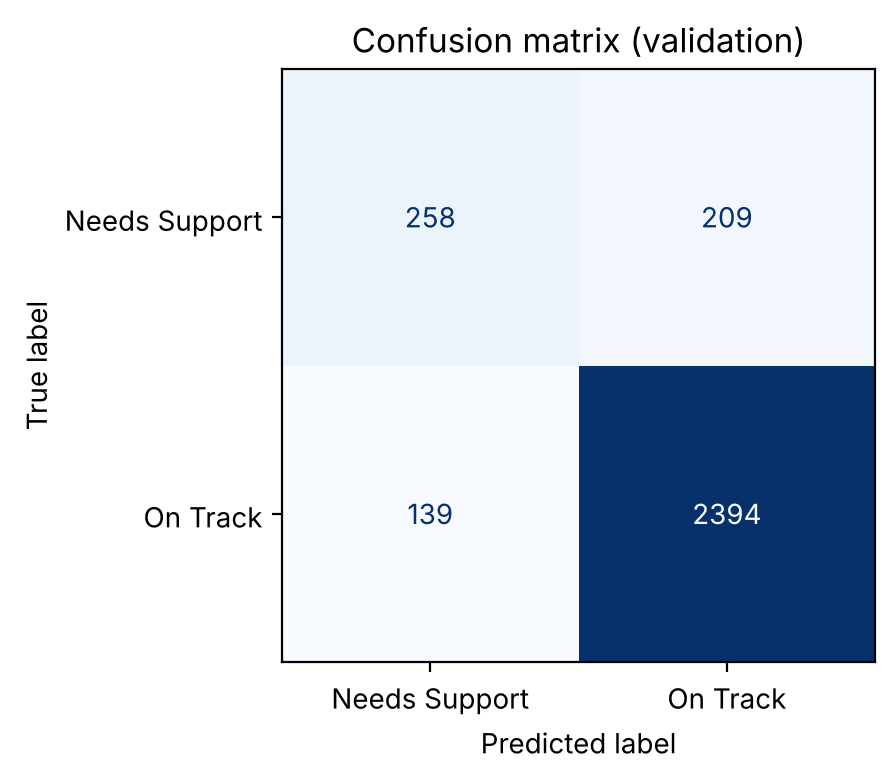

Assignment target (85-90% validation accuracy, gap <= 5 points): MET


In [6]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

train_acc = accuracy_score(y_train, pipeline.predict(X_train))
valid_pred = pipeline.predict(X_valid)
valid_acc = accuracy_score(y_valid, valid_pred)
baseline = (y_valid == "On Track").mean()

print(f"Training accuracy  : {train_acc*100:.2f}%")
print(f"Validation accuracy: {valid_acc*100:.2f}%")
print(f"Gap                : {abs(train_acc-valid_acc)*100:.2f} points")
print(f"Baseline (always On Track): {baseline*100:.2f}%")
print()
print(classification_report(y_valid, valid_pred, digits=3))

fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay(confusion_matrix(y_valid, valid_pred, labels=classes), display_labels=classes).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Confusion matrix (validation)")
plt.tight_layout(); plt.show()

rubric_ok = 0.85 <= valid_acc <= 0.90 and abs(train_acc - valid_acc) <= 0.05
print("Assignment target (85-90% validation accuracy, gap <= 5 points):", "MET" if rubric_ok else "NOT MET")

**Reading the result.** Accuracy is only modestly above the always-On-Track baseline, because most students are On Track. Recall for *Needs Support* matters more for a support tool: it shows how many students who need help the model catches. See the table above.

## 7. Which habits matter most?

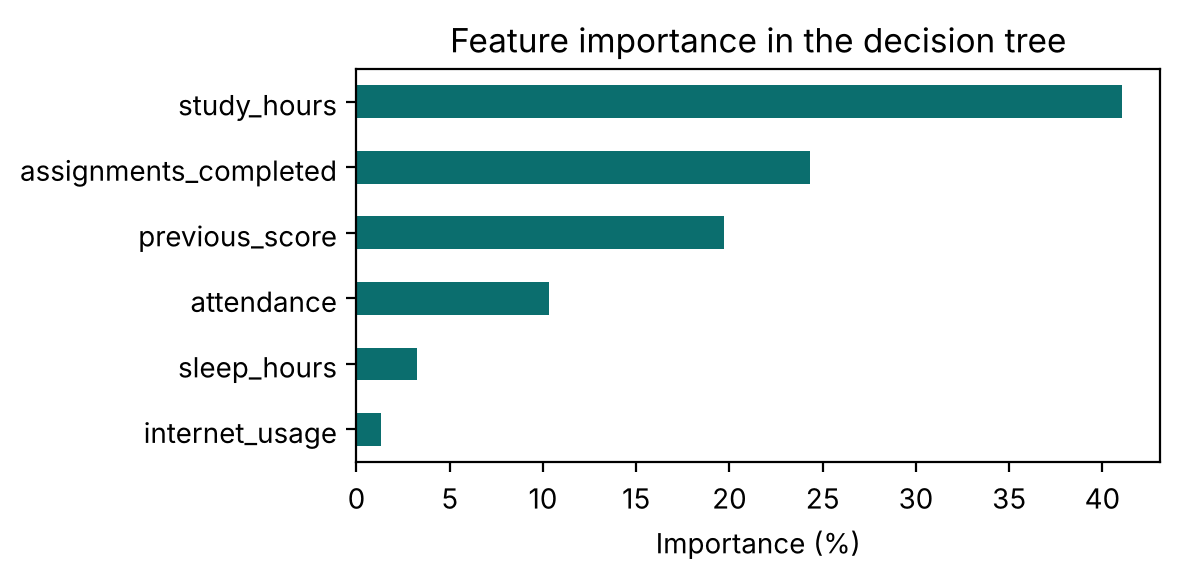

Importance shows what the tree used to split. It does not prove that a habit causes a score.


In [7]:
importance = pd.Series(pipeline.named_steps["classifier"].feature_importances_, index=features).sort_values()
ax = importance.mul(100).plot.barh(figsize=(6, 3), color="#0b6e6e")
ax.set_xlabel("Importance (%)"); ax.set_title("Feature importance in the decision tree")
plt.tight_layout(); plt.show()
print("Importance shows what the tree used to split. It does not prove that a habit causes a score.")

## 8. See the tree

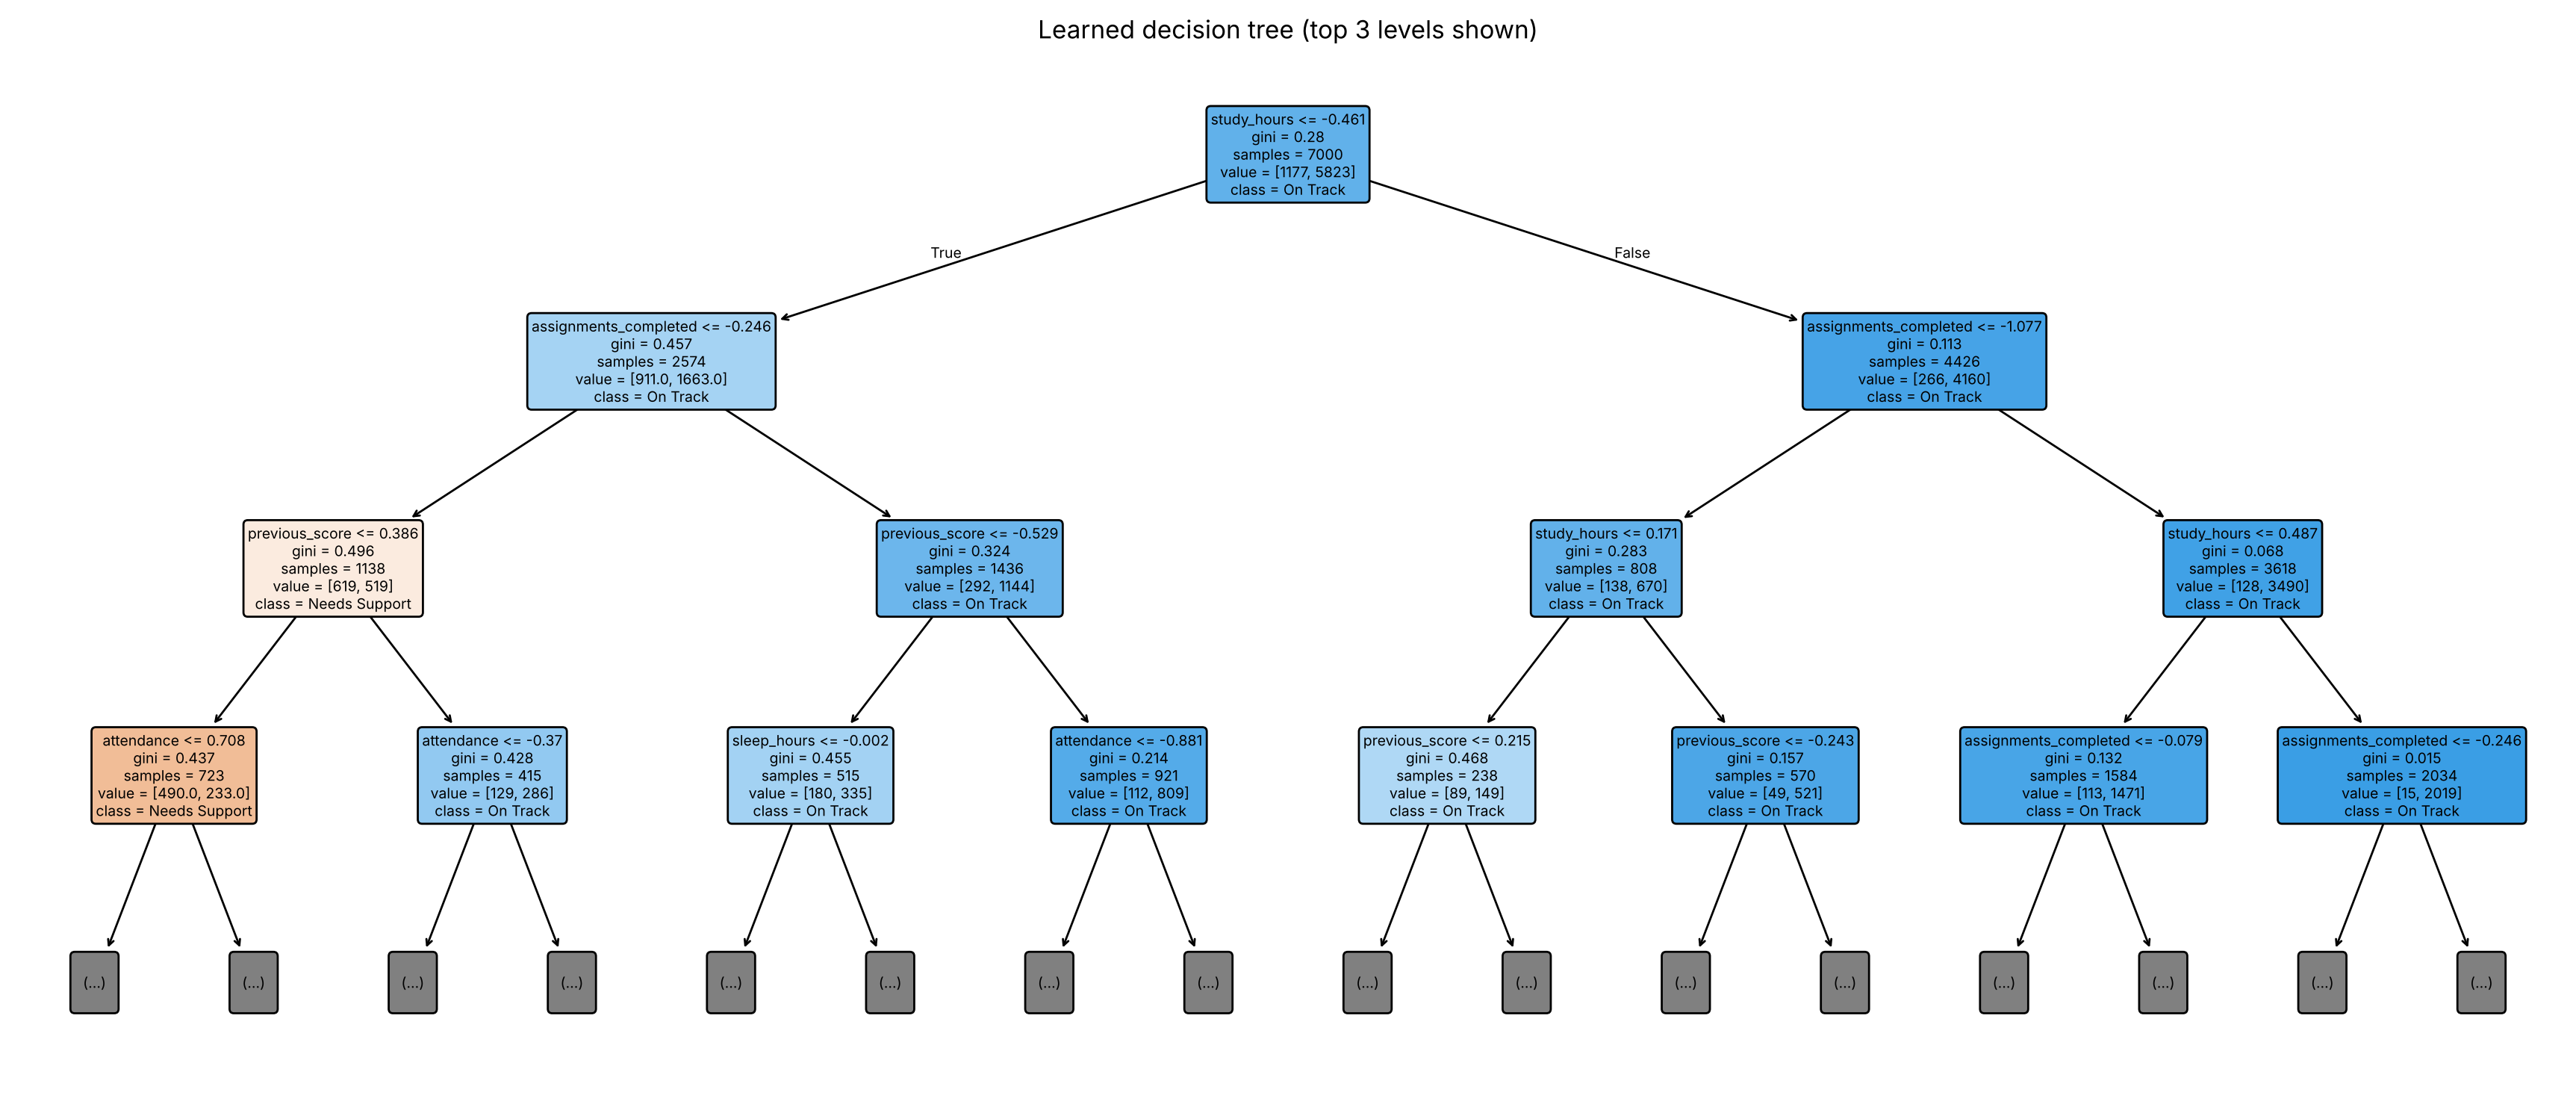

Nodes: 63 | Leaves: 32 | Depth: 5


In [8]:
from sklearn.tree import plot_tree
tree_model = pipeline.named_steps["classifier"]
fig, ax = plt.subplots(figsize=(22, 9))
plot_tree(tree_model, feature_names=features, class_names=classes, filled=True, rounded=True, fontsize=7, max_depth=3, ax=ax)
plt.title("Learned decision tree (top 3 levels shown)"); plt.show()
print("Nodes:", tree_model.tree_.node_count, "| Leaves:", tree_model.get_n_leaves(), "| Depth:", tree_model.get_depth())

## 9. Optional comparison: Logistic Regression
Same split, same pipeline idea. It is shown only for comparison and is not exported to the website.

In [9]:
from sklearn.linear_model import LogisticRegression
logit = Pipeline([("scaler", StandardScaler()), ("classifier", LogisticRegression(max_iter=1000))]).fit(X_train, y_train)
print(f"Decision tree validation accuracy       : {valid_acc*100:.2f}%")
print(f"Logistic regression validation accuracy : {accuracy_score(y_valid, logit.predict(X_valid))*100:.2f}%")

Decision tree validation accuracy       : 88.40%
Logistic regression validation accuracy : 91.07%


## 10. Export the model for the website
`model.js` contains the fitted scaler and every tree node, including the share of training students in each leaf. The website uses these numbers to show a percentage and the questions the tree asked. The last cell checks that the exported tree gives the same answer as scikit-learn for every one of the 10,000 rows.

In [10]:
import sklearn
tree = tree_model.tree_
scaler = pipeline.named_steps["scaler"]

model = {
    "schemaVersion": 5,
    "source": "ClearPath_Decision_Tree.ipynb",
    "algorithm": f"Pipeline(StandardScaler, DecisionTreeClassifier(max_depth={chosen_depth}, min_samples_leaf=50, random_state=42))",
    "sklearnVersion": sklearn.__version__,
    "features": features,
    "classes": classes,
    "ranges": {name: {"min": float(X[name].min()), "max": float(X[name].max()), "median": float(X[name].median())} for name in features},
    "scaler": {"mean": scaler.mean_.tolist(), "scale": scaler.scale_.tolist()},
    "tree": {
        "feature": tree.feature.tolist(),
        "threshold": tree.threshold.tolist(),
        "left": tree.children_left.tolist(),
        "right": tree.children_right.tolist(),
        # share of training students in each class at every node (sums to 1)
        "share": (tree.value[:, 0, :] / tree.value[:, 0, :].sum(axis=1, keepdims=True)).tolist(),
        "samples": tree.n_node_samples.tolist(),
    },
    "metrics": {
        "trainingAccuracy": float(train_acc), "validationAccuracy": float(valid_acc),
        "gap": float(abs(train_acc - valid_acc)), "baseline": float(baseline),
        "recallNeedsSupport": float((valid_pred[y_valid == "Needs Support"] == "Needs Support").mean()),
        "precisionNeedsSupport": float((y_valid[valid_pred == "Needs Support"] == "Needs Support").mean()),
        "trainRows": int(len(X_train)), "validRows": int(len(X_valid)), "rows": int(len(X)),
    },
}
Path("model.js").write_text(
    "/* Generated by ClearPath_Decision_Tree.ipynb. Do not edit by hand: rerun the notebook instead. */\n"
    "window.CLEARPATH_MODEL = " + json.dumps(model, indent=1) + ";\n"
)

# Consistency check: walk the exported tree in Python exactly as the website does, and compare with scikit-learn.
def walk(row):
    z = ((row - scaler.mean_) / scaler.scale_).astype(np.float32)
    node = 0
    while tree.children_left[node] != -1:
        node = tree.children_left[node] if z[tree.feature[node]] <= np.float32(tree.threshold[node]) else tree.children_right[node]
    return classes[int(np.argmax(tree.value[node, 0]))]

exported = np.array([walk(r) for r in X.to_numpy(dtype=float)])
assert (exported == pipeline.predict(X)).all()
print("Exported tree matches scikit-learn on all", len(X), "rows. model.js written.")

try:
    from google.colab import files
    files.download("model.js")
except ImportError:
    pass

Exported tree matches scikit-learn on all 10000 rows. model.js written.


## 11. Try two example students

In [11]:
examples = pd.DataFrame([
    [8, 90, 7, 4, 16, 70],     # strong habits
    [2, 55, 5, 9, 3, 50],      # weak habits
], columns=features)
proba = pipeline.predict_proba(examples)
examples["prediction"] = pipeline.predict(examples)
examples["chance_on_track_%"] = (proba[:, list(pipeline.classes_).index("On Track")] * 100).round(0)
examples

,study_hours,attendance,sleep_hours,internet_usage,assignments_completed,previous_score,prediction,chance_on_track_%
0,8,90,7,4,16,70,On Track,100.0
1,2,55,5,9,3,50,Needs Support,13.0


## Limitations
* The dataset looks simulated: every label equals one exam rule, and about a third of exam scores sit at exactly 100. It must be replaced with real, consented records before anyone relies on the results.
* The units of `study_hours` and `internet_usage` are unconfirmed.
* Patterns in the data are associations, not causes. A habit change is not guaranteed to change a score.
* One validation split of 3,000 rows is used for reporting. No separate final test set was supplied.
* Accuracy should be checked for each student group before any real intervention.
* The app is for academic demonstration and for starting a conversation about support. It must not be used to grade, rank or label students.